# Ronan SANDI fit performance evaluations



In [1]:
from pathlib import Path
import sys

def find_repo_root(start: Path) -> Path:
    for candidate in [start, *start.parents]:
        if (candidate / "src").exists():
            return candidate
    raise RuntimeError("Could not locate repository root containing src/.")

repo_root = find_repo_root(Path.cwd().resolve())
src_path = repo_root / "src"
if str(src_path) not in sys.path:
    sys.path.insert(0, str(src_path))

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
import pandas as pd

from dmri_models.acquisitions import rm_full
from dmri_models.acquisitions import rm_no_b0p5
from dmri_models.acquisitions import rm_no_b5
from dmri_models.acquisitions import rm_no_b4_or_b5
from dmri_models.acquisitions import rm_no_b3_b4_or_b5
from dmri_models.acquisitions import rm_no_b4
from dmri_models.acquisitions import rm_no_b3_or_b4
from dmri_models.acquisitions import rm_no_b2_or_b4
from dmri_models.acquisitions import uk_biobank
from dmri_models.acquisitions import rm_30dirs
from dmri_models.acquisitions import rm_50dirs
from dmri_models.acquisitions import rm_60dirs
from dmri_models.acquisitions import rm_inc_dirs_high
from dmri_models.acquisitions import rm_inc_dirs_mod
from dmri_models.acquisitions import rm_inc_dirs_low

from dmri_models import (
    Acquisition, Ball, Component, EmceeFitter, GaussianNoise,
    LeastSquaresFitter, Model, Sphere, Stick, sandi,
)
from dmri_models.acquisitions import sandi_full_acq

rng = np.random.default_rng(21)


## Save each stored acquisition within the list and print a summary of the details for each

In [2]:
# --- Acquisition variants ----------------------------------------------------
acquisitions = {
    "rm_full": rm_full(),
    "sandi_full": sandi_full_acq(),
    "rm_30dirs": rm_30dirs(),
    "rm_50dirs": rm_50dirs(),
    "rm_60dirs": rm_60dirs(),
    "rm_inc_dirs_high": rm_inc_dirs_high(),
    "rm_inc_dirs_mod": rm_inc_dirs_mod(),
    "rm_inc_dirs_low": rm_inc_dirs_low(),
}

for name, acq in acquisitions.items():
    print(f"\n{name}")
    acq.print_summary()


rm_full
----------------------------------------------------------------
Acquisition summary
- measurements: 200
- b-value shells (ms/um^2): 7 (tolerance: 0.100)
  - b=0.000: 20 measurements, 0 non-zero directions
  - b=0.500: 30 measurements, 30 non-zero directions
  - b=1.000: 30 measurements, 30 non-zero directions
  - b=2.000: 30 measurements, 30 non-zero directions
  - b=3.000: 30 measurements, 30 non-zero directions
  - b=4.000: 30 measurements, 30 non-zero directions
  - b=5.000: 30 measurements, 30 non-zero directions
- gradient directions: 180 unique non-zero across 180 diffusion-weighted measurements
- b-tensor shape: 1.000
- pulse duration (ms): 5.000
- diffusion time (ms): 12.000
- gradient strength (T/m): 0.000 to 0.520
- echo time (ms): 26.000
- inversion time: n/a
- repetition time (ms): 2500.000
----------------------------------------------------------------

sandi_full
----------------------------------------------------------------
Acquisition summary
- measurements

## SANDI setup

In [3]:
rng = np.random.default_rng(11)

preset = sandi(
    d_sphere=3.0,
    d_in=2.0,
    d_ex=1.5,
)

model = preset.model
parameter_space = preset.parameters

true_parameters = parameter_space.initial_values()
true_parameters.update(
    {
        "S0": 1.0,
        "r_soma": 7.0,
        "d_sphere": 3.0,
        "d_in": 2.0,
        "d_ex": 1.5,
        "soma_fraction": 0.22,
        "neurite_fraction": 0.50,
        "extra_fraction": 0.28,
    }
)

SNR = 20.0
sigma = true_parameters["S0"] / SNR

## Simulate the data from each acquisition

In [4]:
# -----------------------------------------------------------------------------
# Simulate directional and spherical-mean data for each acquisition
# -----------------------------------------------------------------------------
datasets = {}

for name, acquisition in acquisitions.items():

    # Simulate directional signal
    signal_true = model.signal(acquisition, true_parameters)
    signal_noisy = signal_true + rng.normal(
        0.0,
        sigma,
        size=signal_true.shape,
    )

    # -------------------------------------------------------------
    # Build spherical mean
    # -------------------------------------------------------------
    b_vals = np.asarray(acquisition.b_values)
    b_shells = np.unique(np.round(b_vals, 4))

    sm_signal = []
    sm_b = []
    n_dirs = []

    for b in b_shells:
        mask = np.abs(b_vals - b) < 1e-4
        sm_signal.append(np.mean(signal_noisy[mask]))
        sm_b.append(b)
        n_dirs.append(mask.sum())

    sm_signal = np.asarray(sm_signal)
    sm_b = np.asarray(sm_b)
    n_dirs = np.asarray(n_dirs)

    sigma_sm = sigma / np.sqrt(n_dirs)

    acq_sm = Acquisition.from_pgse(
        sm_b,
        b_unit="ms/um^2",
        pulse_duration=acquisition.pulse_duration[0],
        diffusion_time=acquisition.diffusion_time[0],
        b_tensor_shape=acquisition.b_tensor_shape[0],
    )

    datasets[name] = {
        "directional_acquisition": acquisition,
        "directional_signal": signal_noisy,
        "directional_signal_true": signal_true,
        "sigma_directional": sigma,
        "sm_acquisition": acq_sm,
        "sm_signal": sm_signal,
        "sigma_sm": sigma_sm,
        "n_dirs": n_dirs,
        "shells": sm_b,
    }

    print(
        f"{name:12s}: "
        f"{acquisition.n_measurements:3d} measurements, "
        f"{acq_sm.n_measurements} shells"
    )

rm_full     : 200 measurements, 7 shells
sandi_full  : 350 measurements, 7 shells
rm_30dirs   : 170 measurements, 6 shells
rm_50dirs   : 270 measurements, 6 shells
rm_60dirs   : 320 measurements, 6 shells
rm_inc_dirs_high: 325 measurements, 6 shells
rm_inc_dirs_mod: 250 measurements, 6 shells
rm_inc_dirs_low: 180 measurements, 6 shells


## The main loop. Fit the model to each acquisition (in parallel across repeats)

In [ ]:
from concurrent.futures import ProcessPoolExecutor, as_completed
from dmri_models.benchmark_utils import (
    run_task,
    fit_one_run_directional,
    fit_one_run_spherical_mean,
    _parameter_errors,
    _optional_odi,
)
import os

results = []
n_repeats = 100
tasks = [
    (acq_name, fit_kind, acq, rep, 1000 + rep)
    for acq_name, acq in acquisitions.items()
    for fit_kind in ("dir", "sm")
    for rep in range(n_repeats)
]

with ProcessPoolExecutor(max_workers=max(1, os.cpu_count() - 1)) as ex:
    futures = [
        ex.submit(
            run_task,
            task,
            fit_one_run_directional,
            true_parameters,
            model,
            parameter_space,
            20.0,
            16,
            2000,
        )
        for task in tasks
    ]
    for fut in as_completed(futures):
        results.append(fut.result())

print(f"Completed {len(results)} attempted fits.")

Completed 1600 attempted fits.


## Convert the results into a DataFrame

In [6]:
df = pd.DataFrame(results)

# Expand fitted parameter dict into columns.
fit_params = pd.json_normalize(df["fit_parameters"])
df = pd.concat([df.drop(columns=["fit_parameters"]), fit_params], axis=1)


truth_map = {
    "S0": true_parameters["S0"],
    "r_soma": true_parameters["r_soma"],
    "d_sphere": true_parameters["d_sphere"],
    "d_in": true_parameters["d_in"],
    "d_ex": true_parameters["d_ex"],
    "soma_fraction": true_parameters["soma_fraction"],
    "neurite_fraction": true_parameters["neurite_fraction"],
    "extra_fraction": true_parameters["extra_fraction"],
}

# Add truth and error columns only for parameters that exist in the fitted results
for key, truth in truth_map.items():
    if key in df.columns:
        df[f"{key}_true"] = truth
        df[f"{key}_error"] = df[key] - truth
        df[f"{key}_abs_error"] = df[f"{key}_error"].abs()

# Optional: check that fractions still sum to 1
frac_cols = ["soma_fraction", "neurite_fraction", "extra_fraction"]
if all(col in df.columns for col in frac_cols):
    df["fraction_sum"] = df[frac_cols].sum(axis=1)
    df["fraction_sum_error"] = df["fraction_sum"] - 1.0

## Quick results summary table

In [7]:
summary = (
    df.groupby(["acquisition", "fit_kind"])
    .agg(
        rmse_median=("rmse", "median"),
        S0_mae=("S0_abs_error", "mean"),
        r_soma_mae=("r_soma_abs_error", "mean"),
        d_sphere_mae=("d_sphere_abs_error", "mean"),
        d_in_mae=("d_in_abs_error", "mean"),
        d_ex_mae=("d_ex_abs_error", "mean"),
        soma_fraction_mae=("soma_fraction_abs_error", "mean"),
        neurite_fraction_mae=("neurite_fraction_abs_error", "mean"),
        extra_fraction_mae=("extra_fraction_abs_error", "mean"),
    )
    .reset_index()
)
summary

,acquisition,fit_kind,rmse_median,S0_mae,r_soma_mae,d_sphere_mae,d_in_mae,d_ex_mae,soma_fraction_mae,neurite_fraction_mae,extra_fraction_mae
0,rm_30dirs,dir,0.049213,0.007364,1.251564,0.0,0.0,0.0,0.092155,0.100401,0.121537
1,rm_30dirs,sm,0.004637,0.007364,1.251565,0.0,0.0,0.0,0.092155,0.100401,0.121537
2,rm_50dirs,dir,0.049543,0.007188,1.071297,0.0,0.0,0.0,0.074997,0.068077,0.104718
3,rm_50dirs,sm,0.003839,0.007188,1.071297,0.0,0.0,0.0,0.074997,0.068077,0.104718
4,rm_60dirs,dir,0.049763,0.007285,0.982540,0.0,0.0,0.0,0.068862,0.058861,0.092522
5,rm_60dirs,sm,0.003262,0.007285,0.982540,0.0,0.0,0.0,0.068862,0.058861,0.092522
6,rm_full,dir,0.049837,0.007494,1.305853,0.0,0.0,0.0,0.098755,0.103549,0.128042
7,rm_full,sm,0.005165,0.007494,1.305847,0.0,0.0,0.0,0.098754,0.103549,0.128042
8,rm_inc_dirs_high,dir,0.049719,0.007660,1.005926,0.0,0.0,0.0,0.066559,0.063503,0.099839
9,rm_inc_dirs_high,sm,0.004628,0.007660,1.005926,0.0,0.0,0.0,0.066559,0.063503,0.099839


## Parameter-wise fitting performance plot

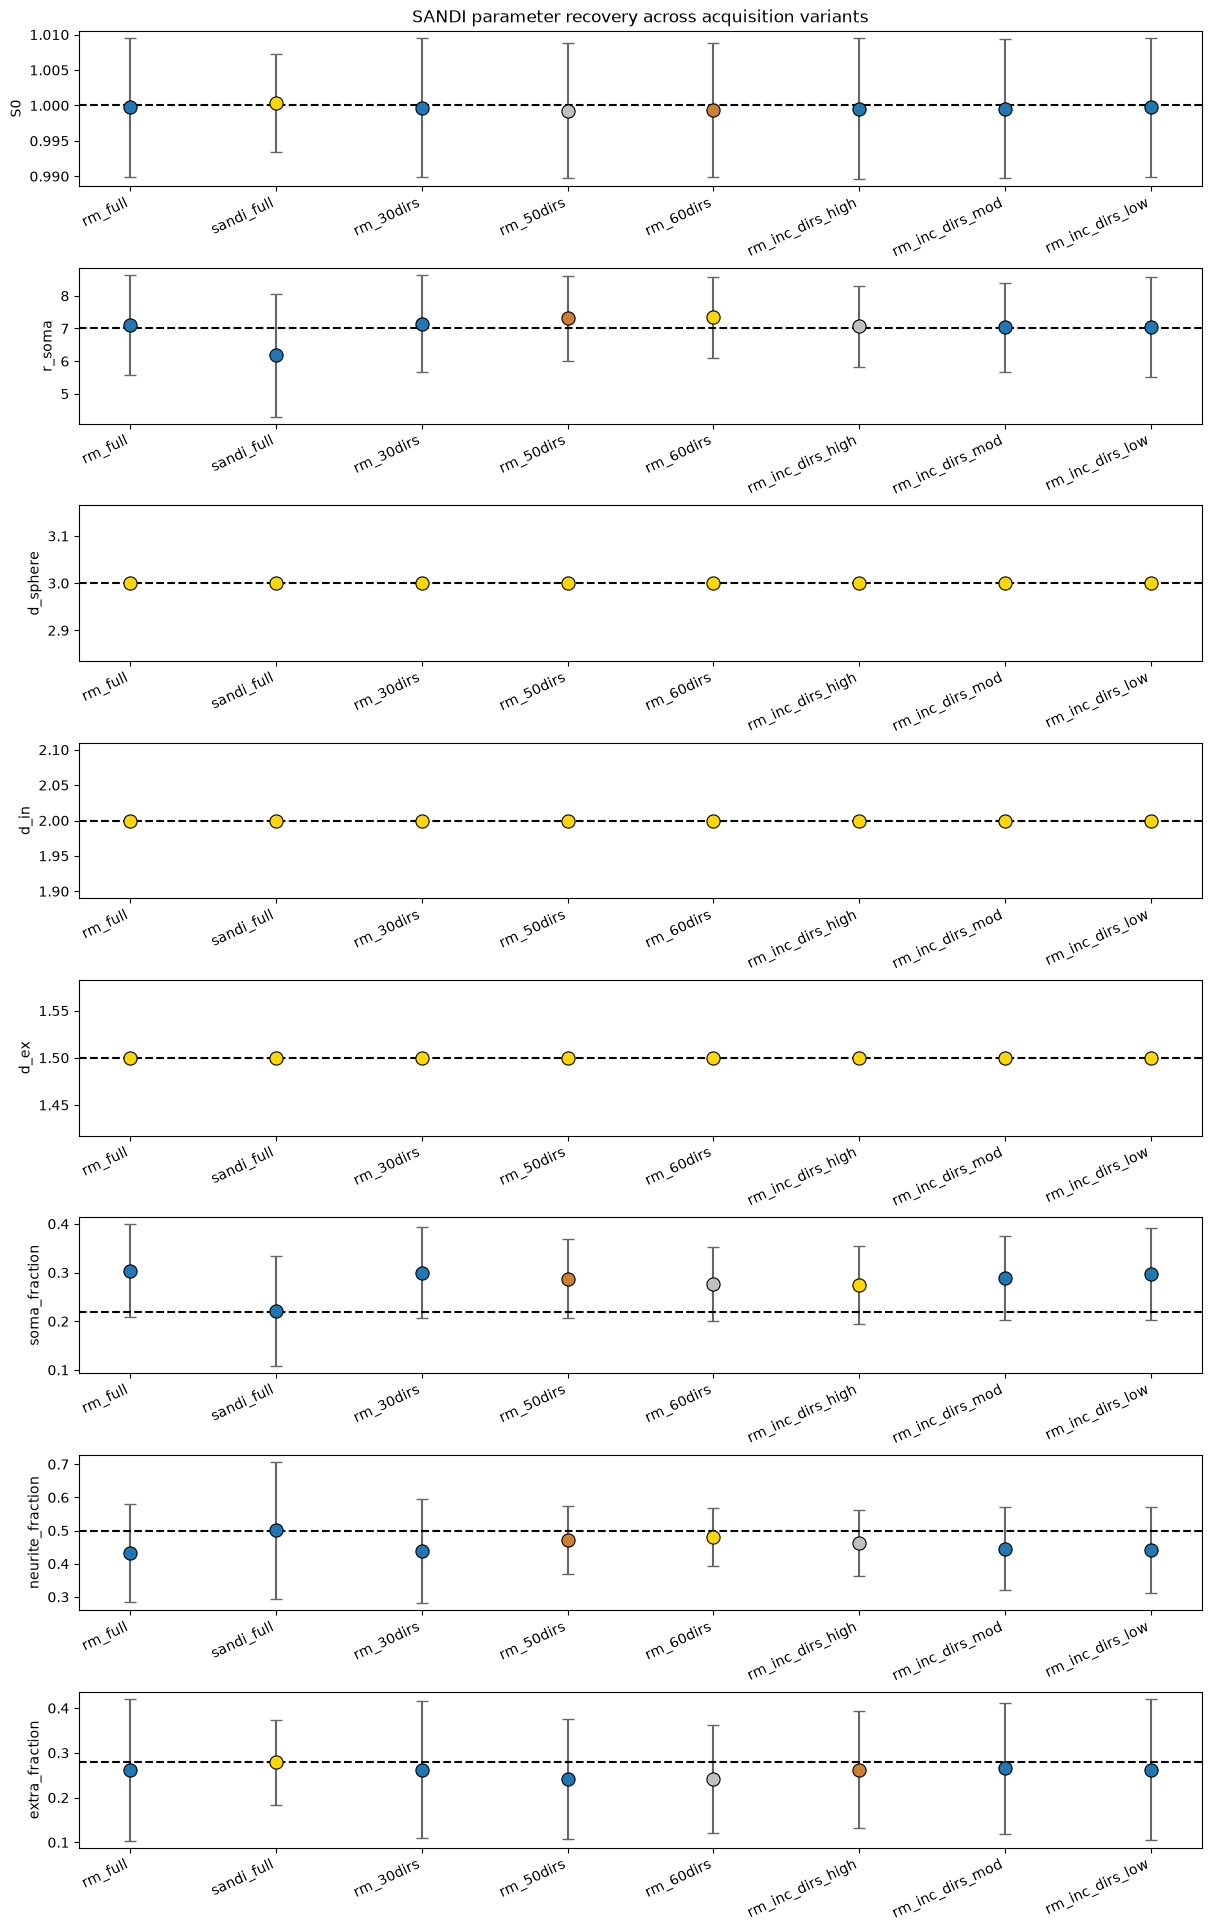

In [8]:
for fit_kind in ["dir", "sm"]:
    subdf = df[df["fit_kind"] == fit_kind].copy()
    # use subdf instead of df in your plotting code

param_names = [
    "S0",
    "r_soma",
    "d_sphere",
    "d_in",
    "d_ex",
    "soma_fraction",
    "neurite_fraction",
    "extra_fraction",
]

truth_lookup = {
    "S0": truth_map["S0"],
    "r_soma": truth_map["r_soma"],
    "d_sphere": truth_map["d_sphere"],
    "d_in": truth_map["d_in"],
    "d_ex": truth_map["d_ex"],
    "soma_fraction": truth_map["soma_fraction"],
    "neurite_fraction": truth_map["neurite_fraction"],
    "extra_fraction": truth_map["extra_fraction"],
}

variants = list(acquisitions.keys())

# Colours for medal ranks
rank_colours = {
    1: "#FFD700",   # gold
    2: "#C0C0C0",   # silver
    3: "#CD7F32",   # bronze
}

# Keep only parameters that are actually present in df and truth_lookup
param_names = [p for p in param_names if p in subdf.columns and p in truth_lookup]

fig, axes = plt.subplots(
    len(param_names),
    1,
    figsize=(12, 2.4 * len(param_names)),
    constrained_layout=True,
)

# If there is only one subplot, make axes iterable
if len(param_names) == 1:
    axes = [axes]

for ax, pname in zip(axes, param_names):

    means = []
    sds = []
    maes = []

    truth = truth_lookup[pname]

    for variant in variants:
        sub = subdf.loc[subdf["acquisition"] == variant, pname].dropna()

        means.append(sub.mean())
        sds.append(sub.std(ddof=1))
        maes.append(np.mean(np.abs(sub - truth)))

    means = np.asarray(means)
    sds = np.asarray(sds)
    maes = np.asarray(maes)

    # Dense ranking: ties share the same rank
    ranks = (
        pd.Series(maes)
        .rank(method="dense", ascending=True)
        .astype(int)
        .values
    )

    x = np.arange(len(variants))

    # Error bars
    ax.errorbar(
        x,
        means,
        yerr=sds,
        fmt="none",
        ecolor="0.4",
        capsize=4,
        zorder=1,
    )

    # Scatter points coloured by MAE rank
    for xi, yi, rank in zip(x, means, ranks):
        colour = rank_colours.get(rank, "tab:blue")
        ax.scatter(
            xi,
            yi,
            s=90,
            color=colour,
            edgecolor="black",
            linewidth=0.8,
            zorder=3,
        )

    ax.axhline(
        truth,
        linestyle="--",
        linewidth=1.5,
        color="black",
        label="Truth",
    )

    ax.set_xticks(x)
    ax.set_xticklabels(variants, rotation=25, ha="right")
    ax.set_ylabel(pname)

axes[0].set_title("SANDI parameter recovery across acquisition variants")
plt.show()

## Residuals coloured by shell

Interpretation guide:

Are the residuals for each shell random? If yes, great! If not, they may be systematically high or low for any given shell. 

If biased on high shells, the model is failing only when diffusion weighting becomes very strong. Means that either our restricted compartment is inadequate or the acquisition is measuring restriction that the model cannot explain.
For neuroinflammation this is exactly what I'd expect if glial restriction becomes important.


rm_full


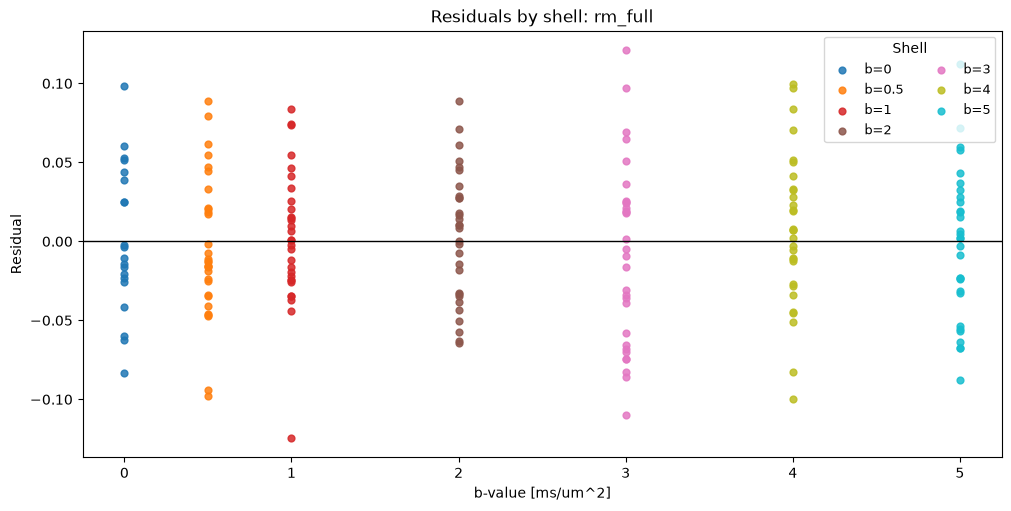


sandi_full


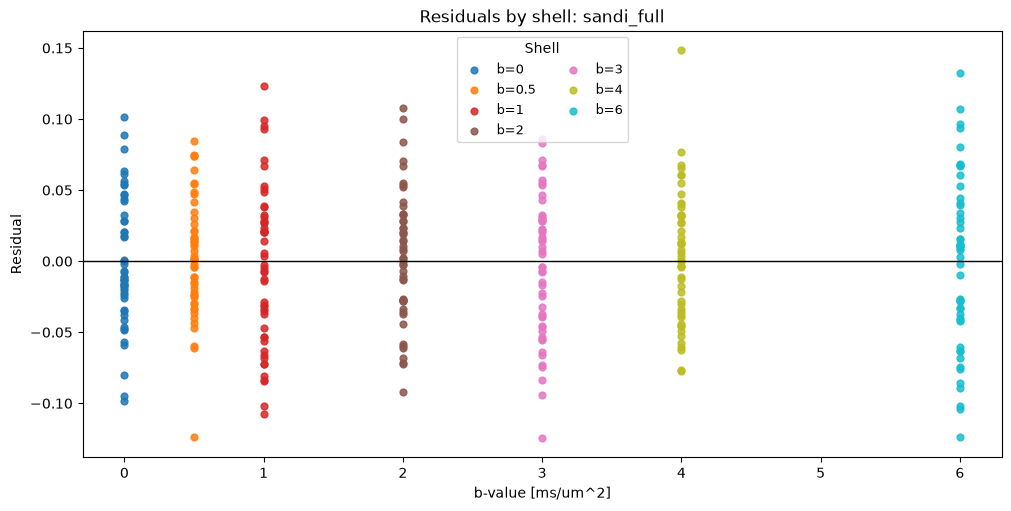


rm_30dirs


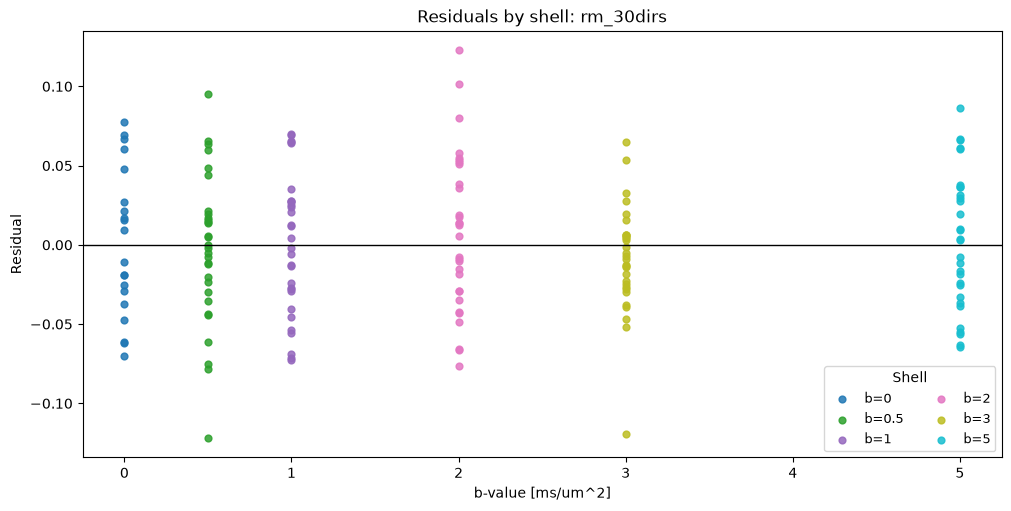


rm_50dirs


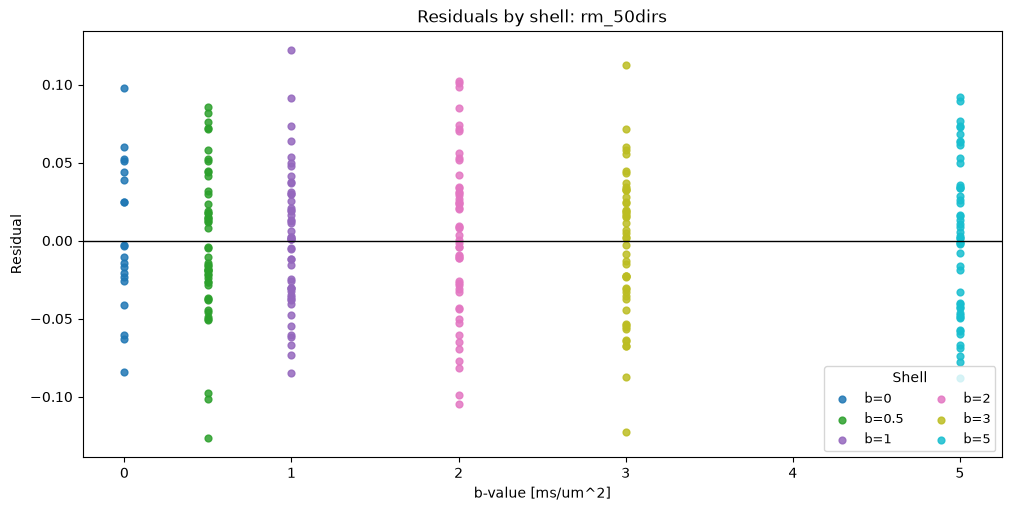


rm_60dirs


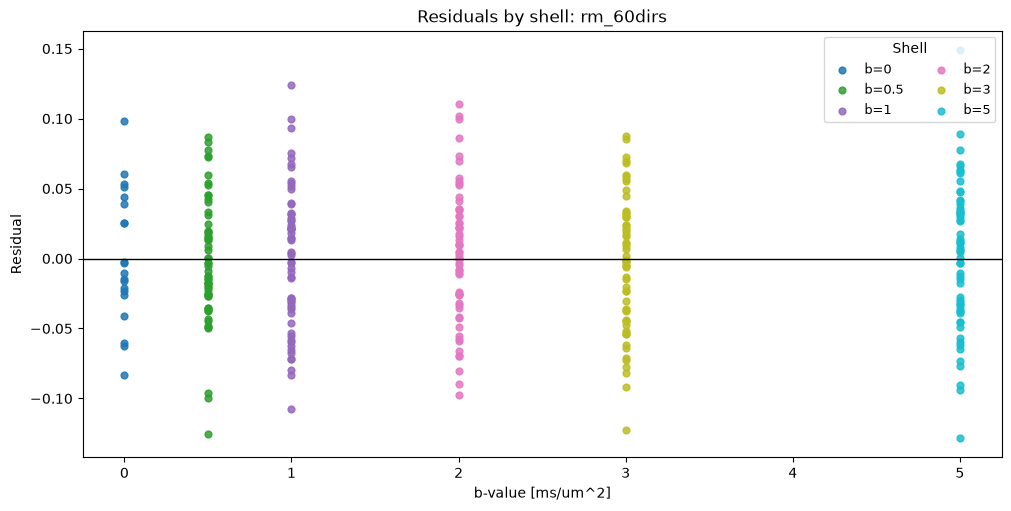


rm_inc_dirs_high


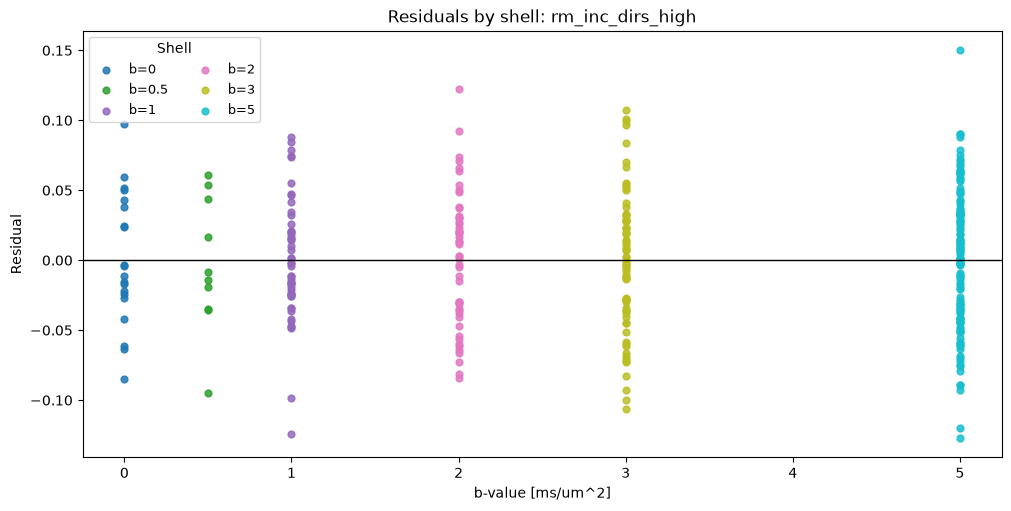


rm_inc_dirs_mod


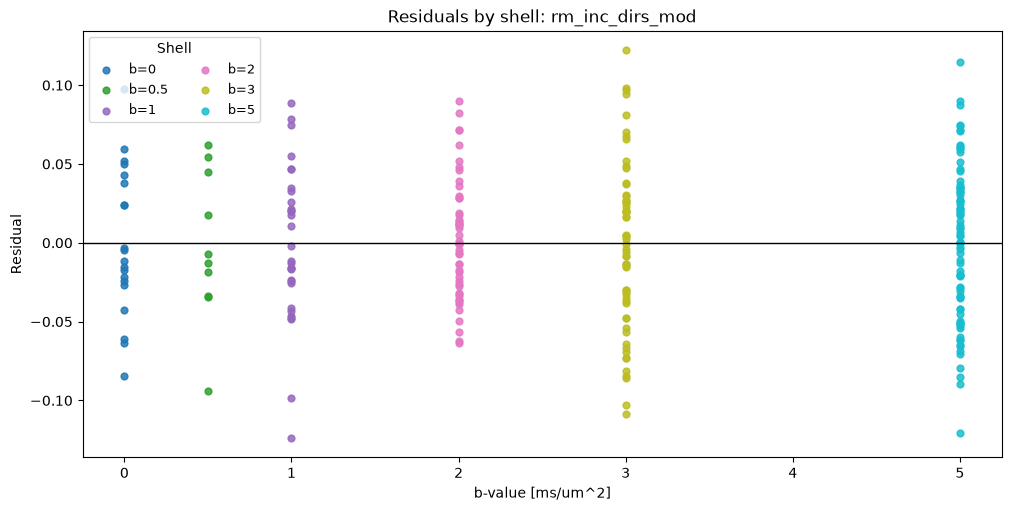


rm_inc_dirs_low


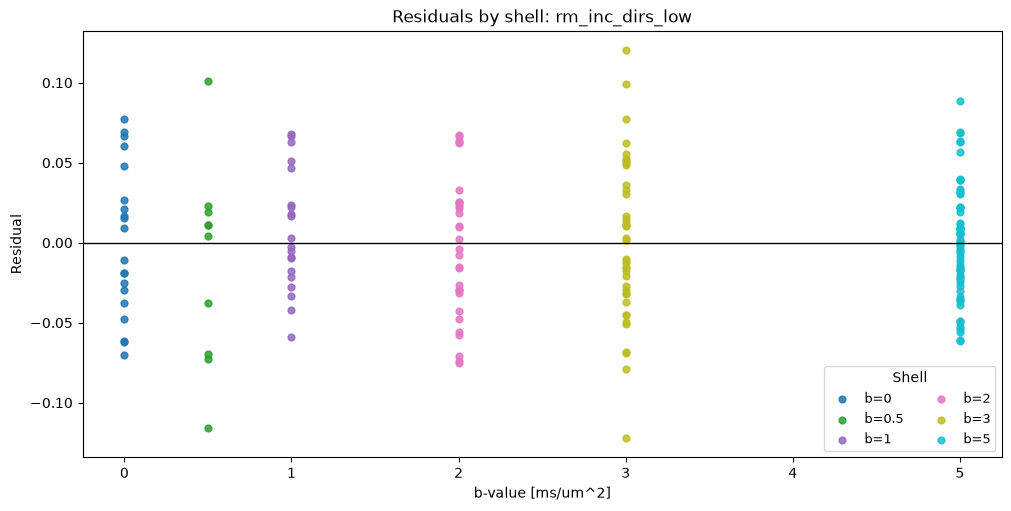

In [9]:
def plot_residuals_by_shell(acq_name: str):
    acq = acquisitions[acq_name]
    sub = df[(df["acquisition"] == acq_name) & (df["success"])].copy()
    if sub.empty:
        print(f"No successful fits found for {acq_name}")
        return

    row = sub.iloc[0]
    bvals = np.asarray(acq.b_values)

    unique_shells = np.unique(np.round(bvals, 4))
    cmap = plt.get_cmap("tab10")

    fig, ax = plt.subplots(figsize=(10, 5), constrained_layout=True)

    for i, shell in enumerate(unique_shells):
        mask = np.isclose(bvals, shell)

        ax.scatter(
            bvals[mask],
            row["residuals"][mask],
            s=24,
            alpha=0.85,
            color=cmap(i / max(1, len(unique_shells)-1)),
            label=f"b={shell:g}",
        )

    ax.axhline(0.0, color="k", linewidth=1)
    ax.set_xlabel("b-value [ms/um^2]")
    ax.set_ylabel("Residual")
    ax.set_title(f"Residuals by shell: {acq_name}")
    ax.legend(title="Shell", ncols=2, fontsize=9)
    plt.show()

for acq_name in acquisitions:
    print(f"\n{'='*80}")
    print(f"{acq_name}")
    print(f"{'='*80}")
    plot_residuals_by_shell(acq_name)

## Parameter correlation matrix

This shows whether the fitted parameters trade off against one another. Plotted for one acquisition at a time.

Interpretation:

strong positive or negative correlations mean parameters are hard to separate;
if kappa and neurite_fraction are strongly correlated, your acquisition may not distinguish dispersion from fraction changes very well;
if d_in and d_csf correlate strongly, diffusivities may be too weakly constrained.


Correlation matrix: rm_full


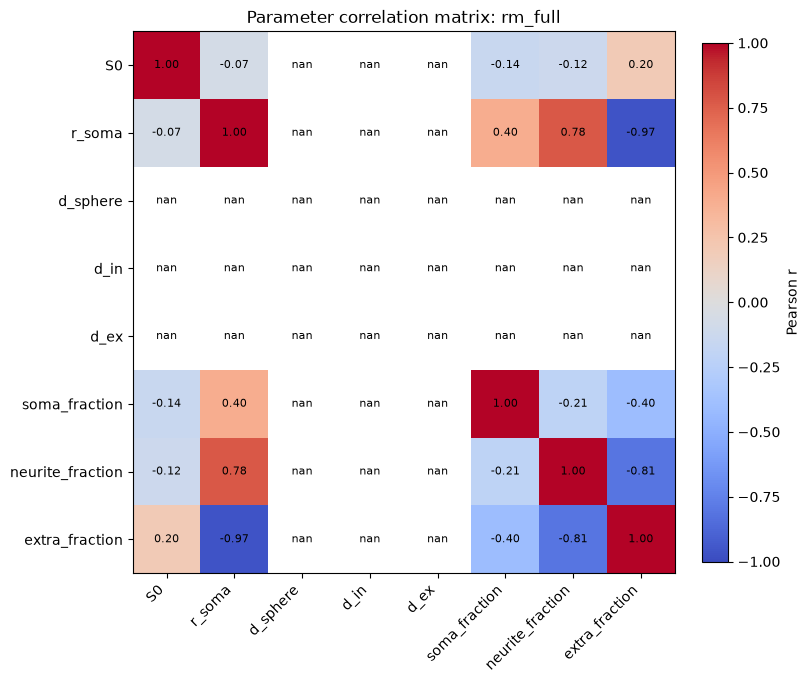


Correlation matrix: sandi_full


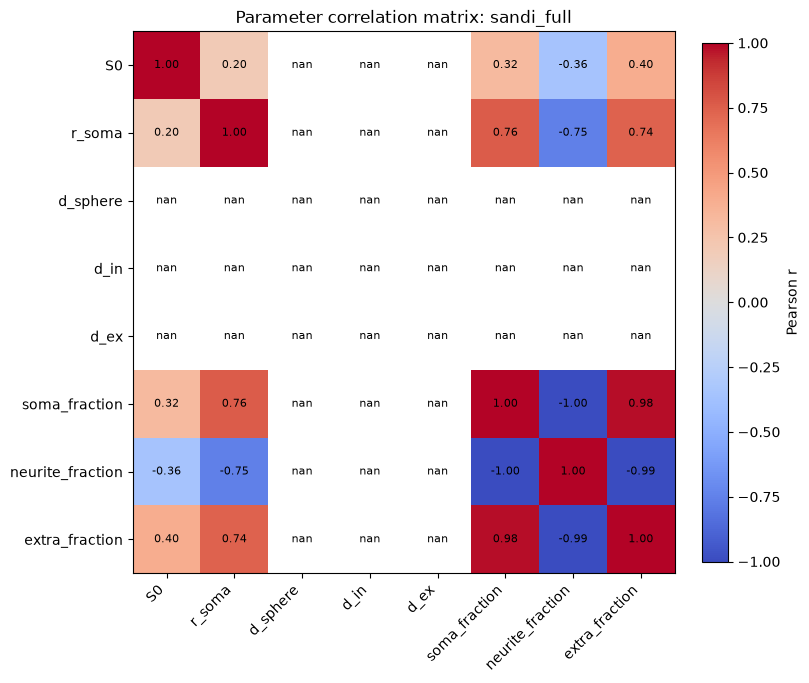


Correlation matrix: rm_30dirs


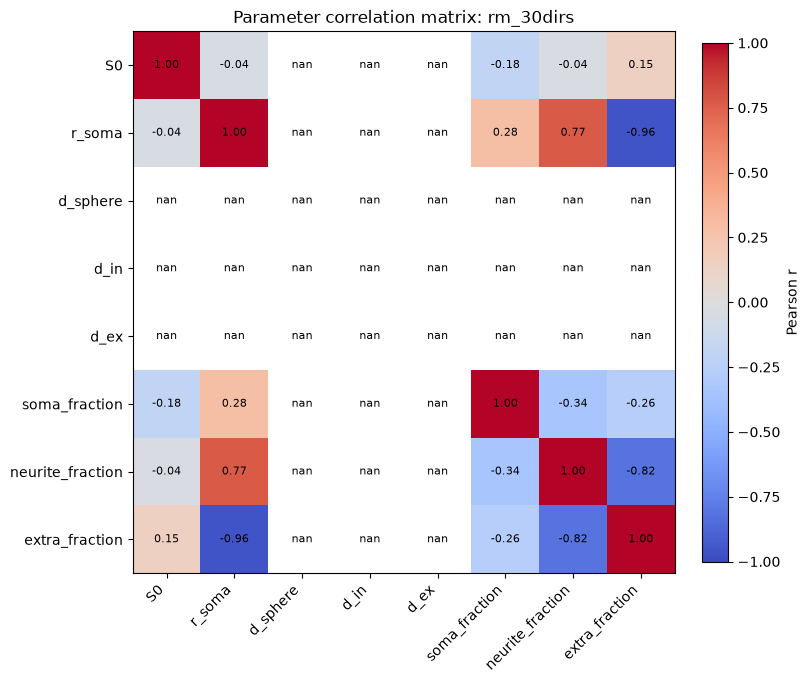


Correlation matrix: rm_50dirs


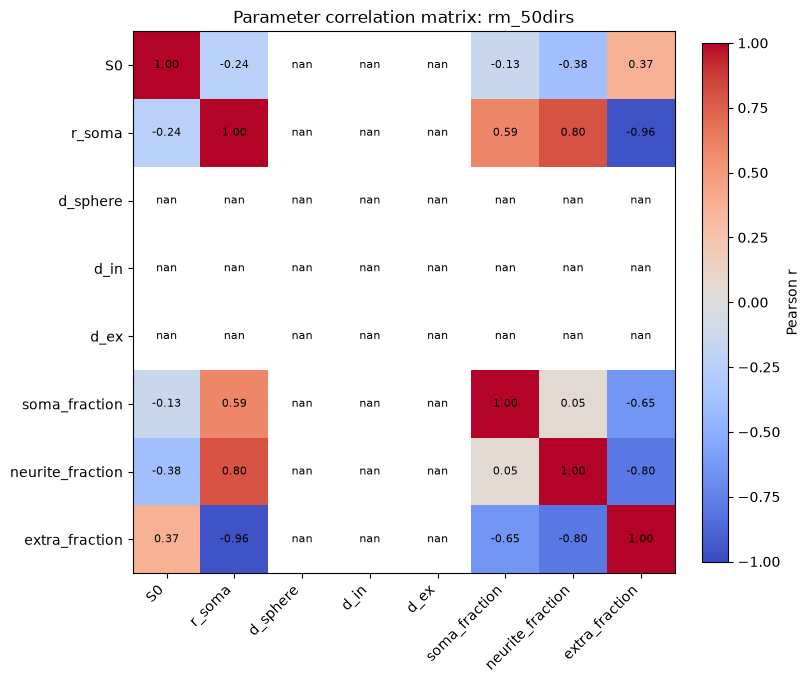


Correlation matrix: rm_60dirs


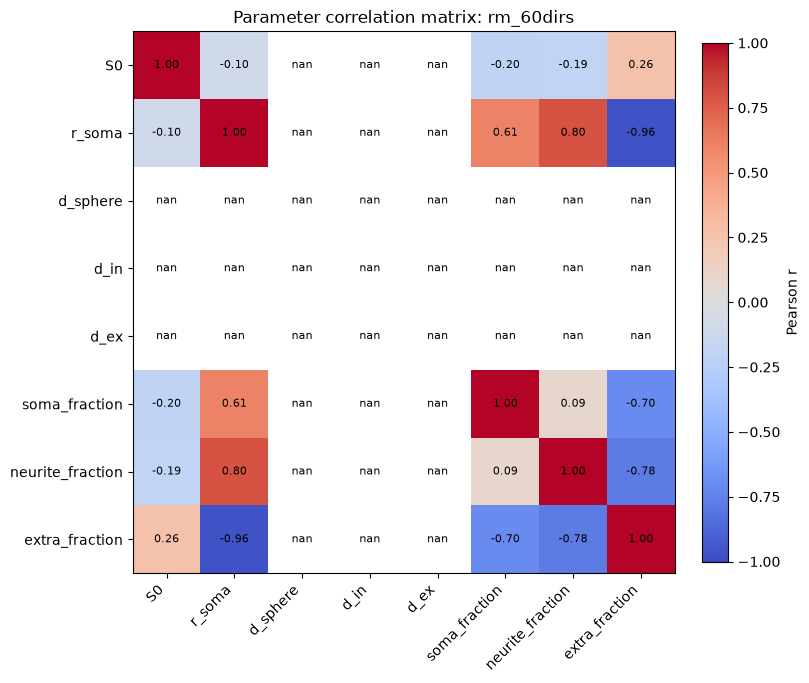


Correlation matrix: rm_inc_dirs_high


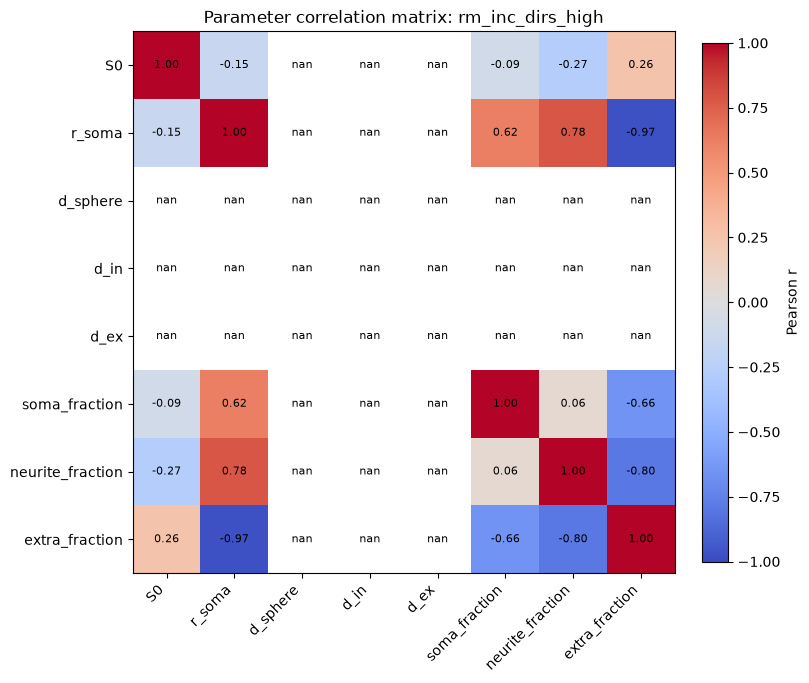


Correlation matrix: rm_inc_dirs_mod


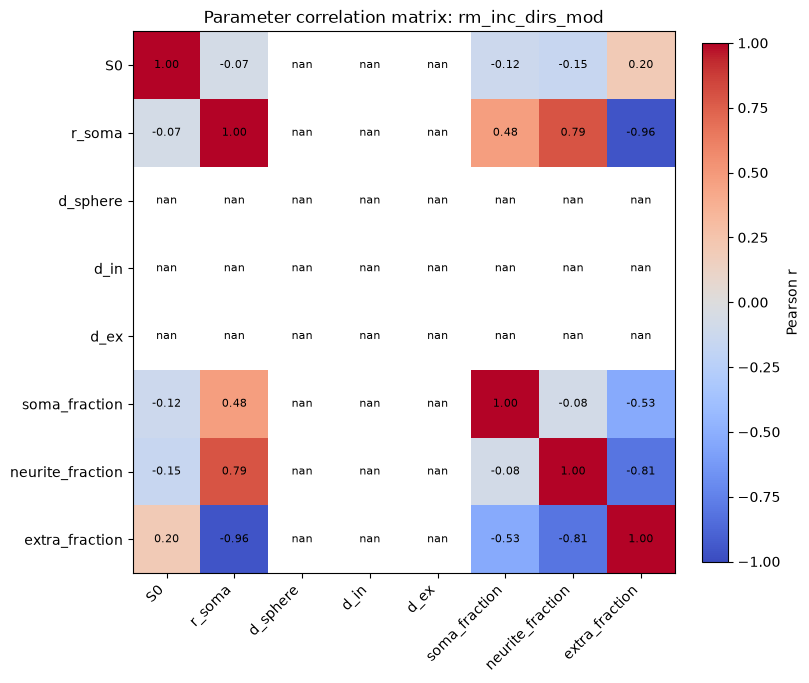


Correlation matrix: rm_inc_dirs_low


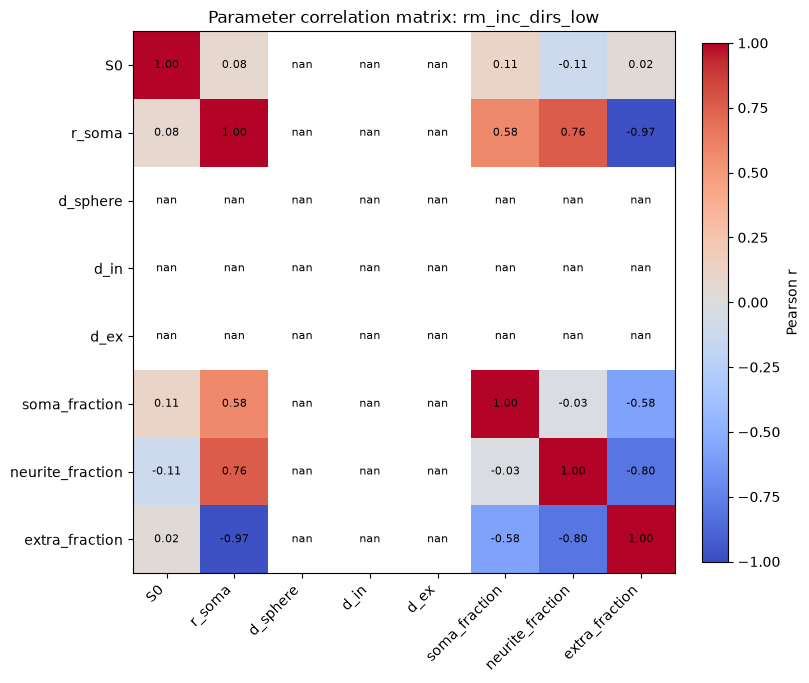

In [10]:
def plot_parameter_correlation(acq_name: str, cols=None):
    if cols is None:
        cols = [    
            "S0",
            "r_soma",
            "d_sphere",
            "d_in",
            "d_ex",
            "soma_fraction",
            "neurite_fraction",
            "extra_fraction",
        ]

    sub = df[df["acquisition"] == acq_name].copy()
    if sub.empty:
        print(f"No rows for acquisition {acq_name}")
        return

    corr = sub[cols].corr()

    fig, ax = plt.subplots(figsize=(8, 7), constrained_layout=True)
    im = ax.imshow(corr.values, vmin=-1, vmax=1, cmap="coolwarm")
    ax.set_xticks(range(len(cols)))
    ax.set_yticks(range(len(cols)))
    ax.set_xticklabels(cols, rotation=45, ha="right")
    ax.set_yticklabels(cols)
    ax.set_title(f"Parameter correlation matrix: {acq_name}")

    for i in range(len(cols)):
        for j in range(len(cols)):
            ax.text(j, i, f"{corr.values[i, j]:.2f}", ha="center", va="center", fontsize=8)

    fig.colorbar(im, ax=ax, shrink=0.85, label="Pearson r")
    plt.show()

for acq_name in acquisitions:
    print(f"\nCorrelation matrix: {acq_name}")
    plot_parameter_correlation(acq_name)

Plot residuals for one representative repeat per acquisition

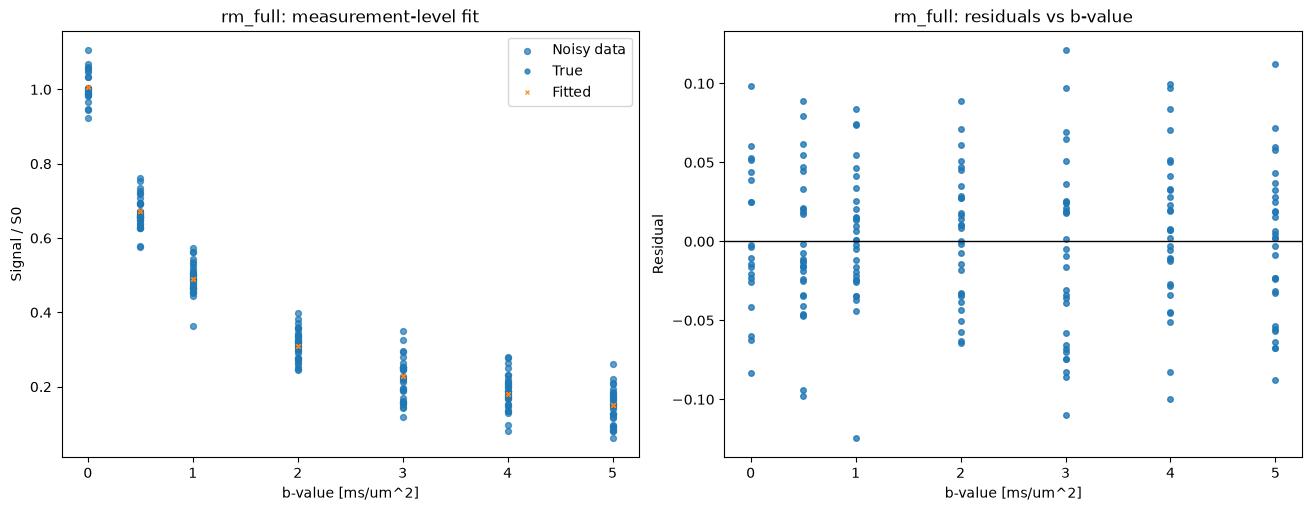

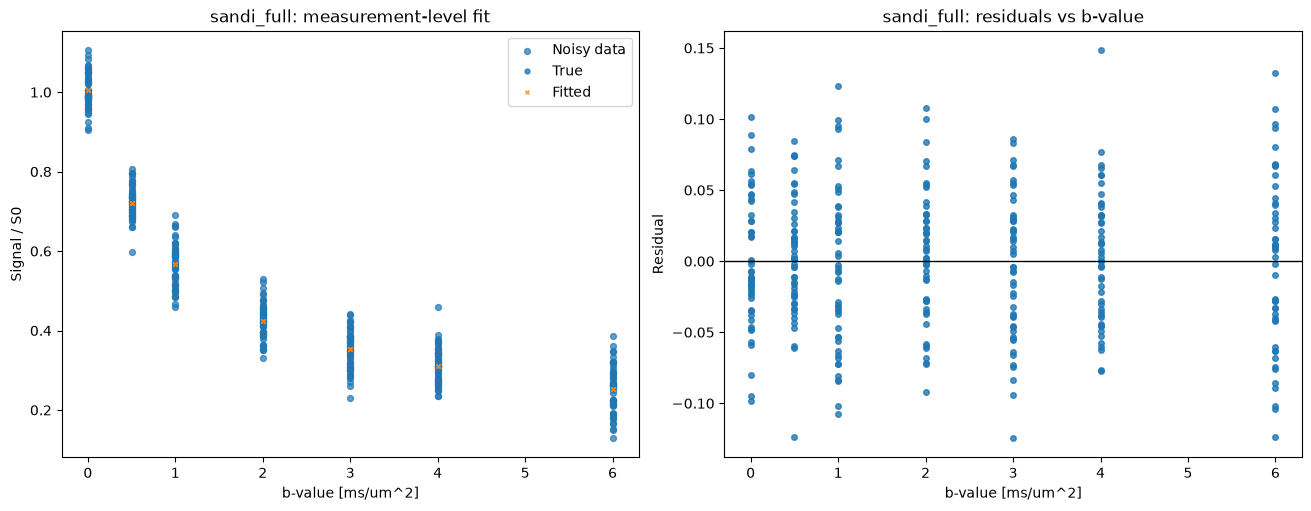

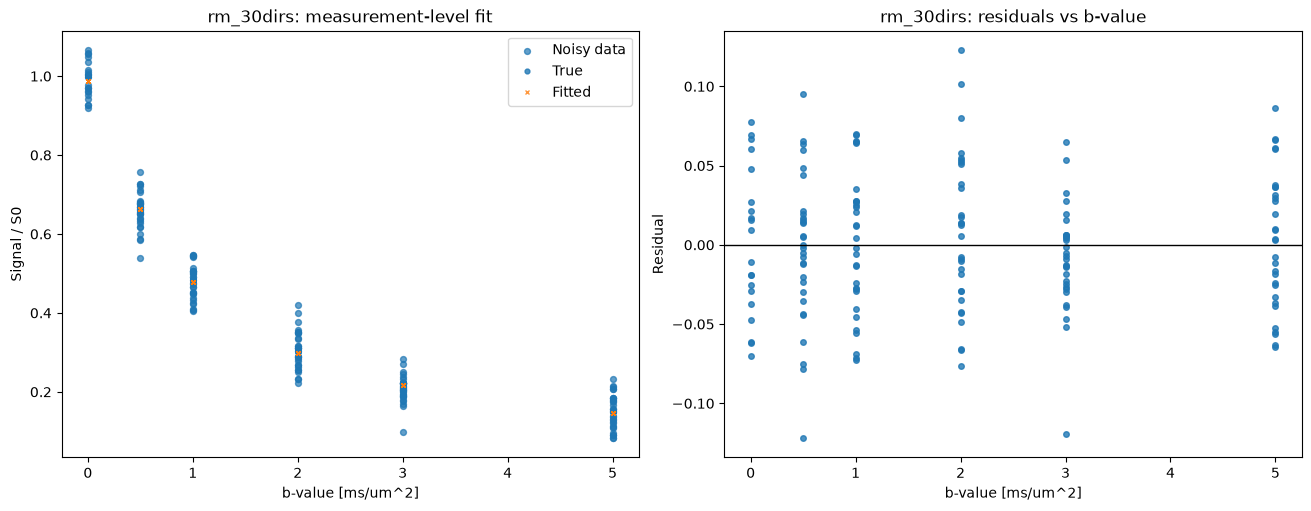

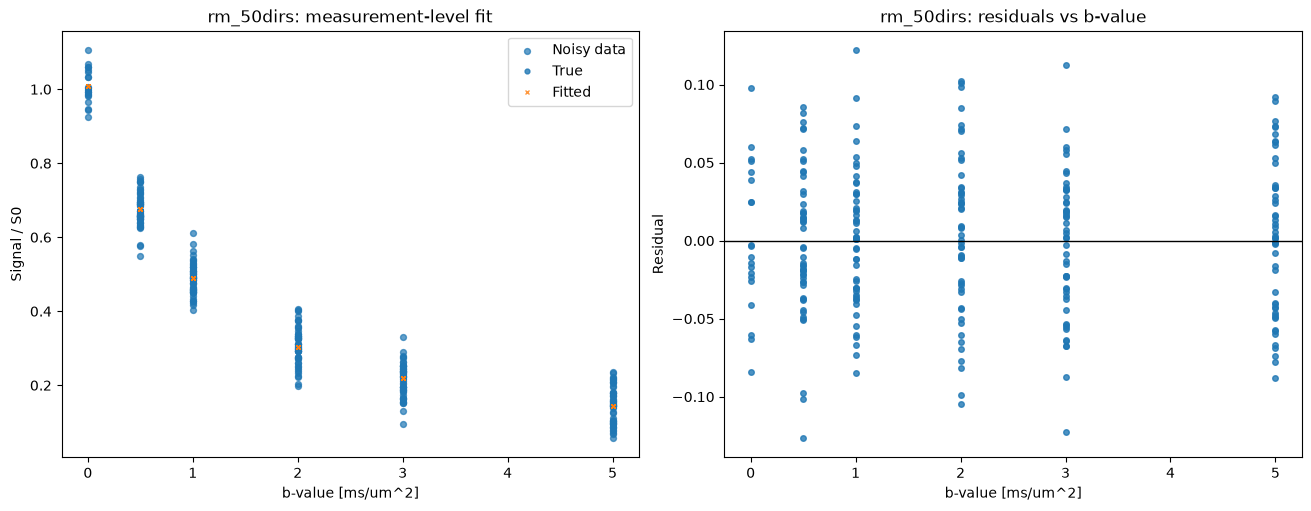

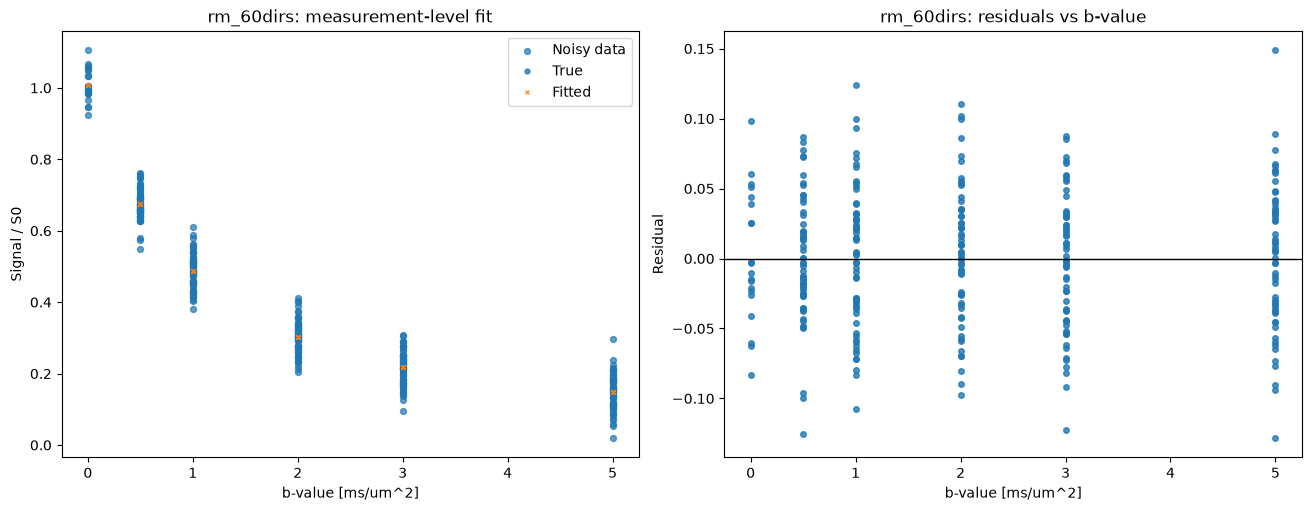

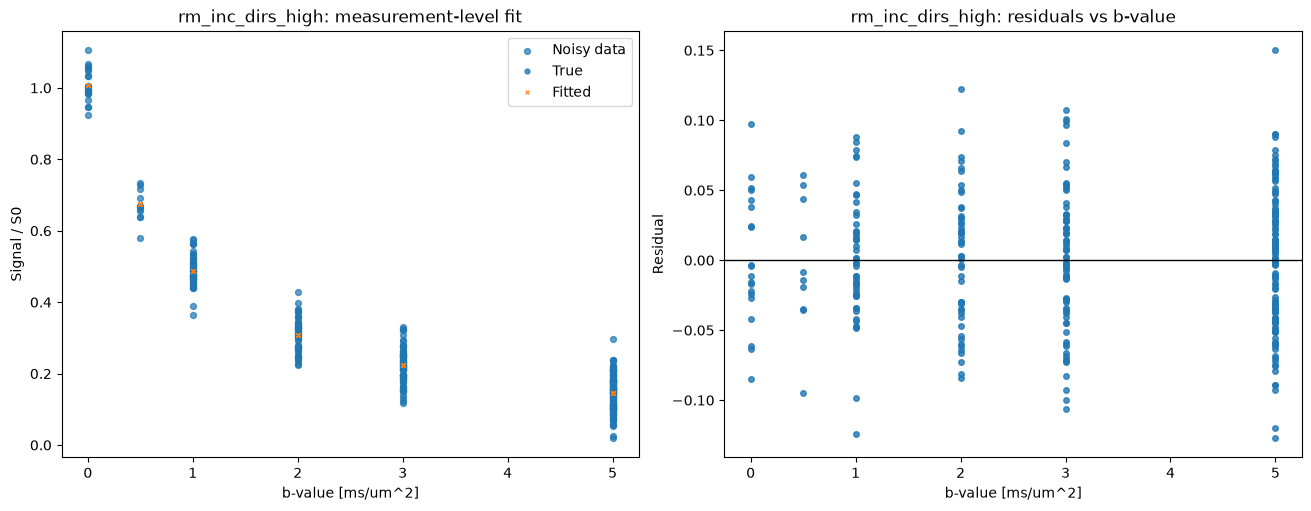

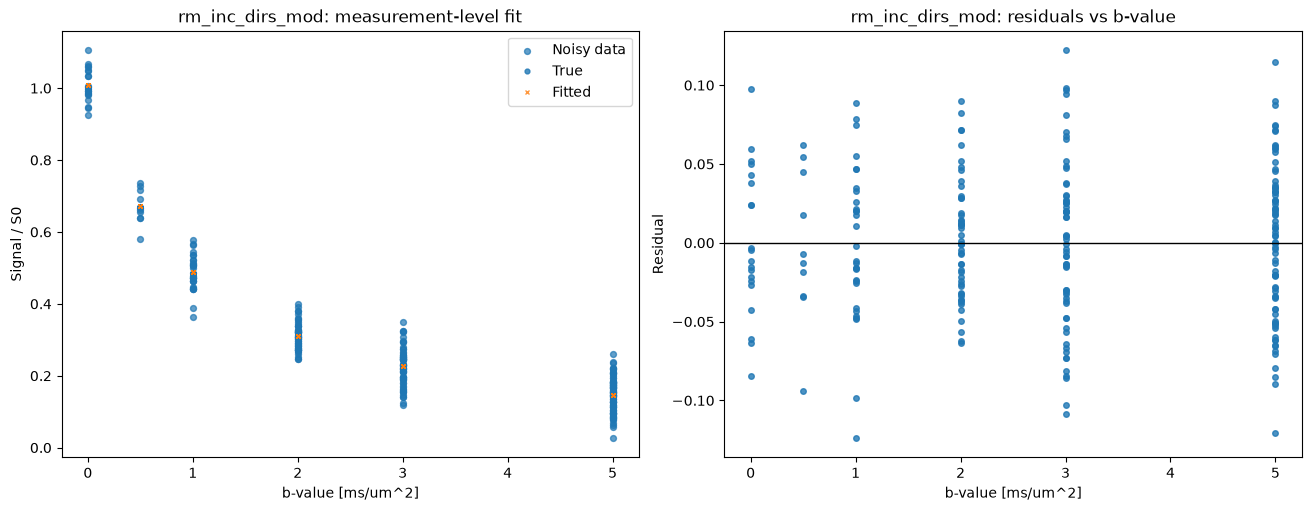

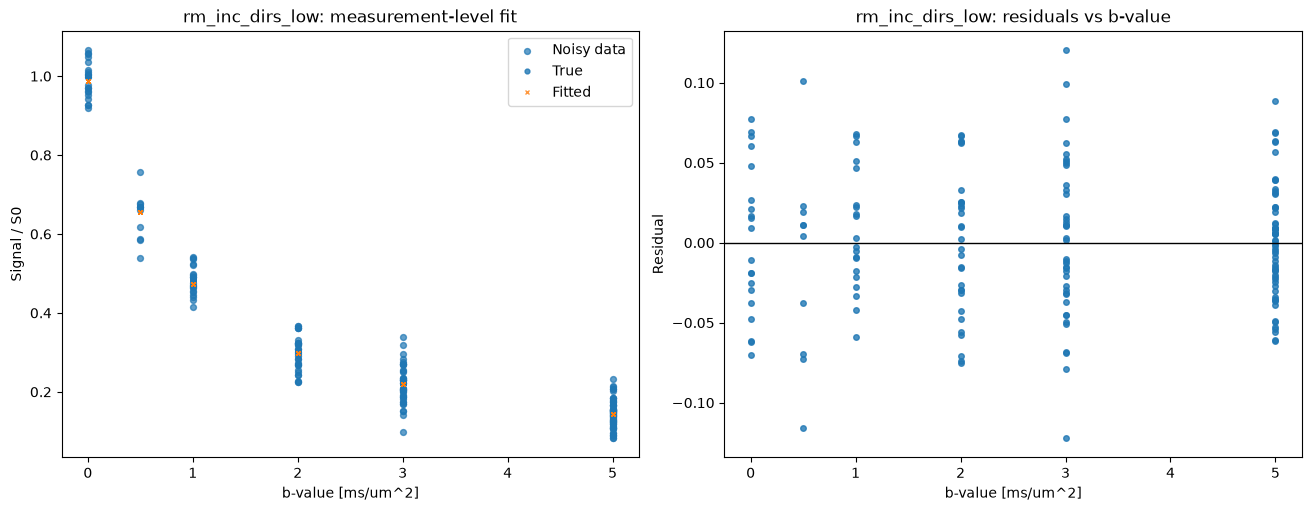

In [11]:
for acq_name in acquisitions.keys():
    row = df[df["acquisition"] == acq_name].iloc[0]

    bvals = acquisitions[acq_name].b_values

    fig, axes = plt.subplots(1, 2, figsize=(13, 5), constrained_layout=True)

    axes[0].scatter(bvals, row["signal_noisy"], s=18, alpha=0.7, label="Noisy data")
    axes[0].plot(bvals, row["signal_true"], "o", markersize=3.5, alpha=0.8, label="True")
    axes[0].plot(bvals, row["predicted"], "x", markersize=3.5, alpha=0.8, label="Fitted")
    axes[0].set_xlabel("b-value [ms/um^2]")
    axes[0].set_ylabel("Signal / S0")
    axes[0].set_title(f"{acq_name}: measurement-level fit")
    axes[0].legend()

    axes[1].scatter(bvals, row["residuals"], s=16, alpha=0.8)
    axes[1].axhline(0.0, color="k", linewidth=1)
    axes[1].set_xlabel("b-value [ms/um^2]")
    axes[1].set_ylabel("Residual")
    axes[1].set_title(f"{acq_name}: residuals vs b-value")

    plt.show()

## Build a summary table of key results

In [12]:
# Keep directional and spherical-mean fits separate
summary = (
    df.groupby(["acquisition", "fit_kind"])
    .agg(
        # Robustness
        success_rate=("success", "mean"),
        n_evaluations_median=("n_evaluations", "median"),
        failure_count=("success", lambda x: int((~x).sum())),

        # Fit quality
        rmse_median=("rmse", "median"),

        # Main accuracy metrics
        S0_mae=("S0_abs_error", "mean"),
        r_soma_mae=("r_soma_abs_error", "mean"),
        d_sphere_mae=("d_sphere_abs_error", "mean"),
        d_in_mae=("d_in_abs_error", "mean"),
        d_ex_mae=("d_ex_abs_error", "mean"),
        soma_fraction_mae=("soma_fraction_abs_error", "mean"),
        neurite_fraction_mae=("neurite_fraction_abs_error", "mean"),
        extra_fraction_mae=("extra_fraction_abs_error", "mean"),

        # Acquisition size bookkeeping
        n_measurements=("n_measurements", "first"),
        n_raw_measurements=("n_raw_measurements", "first"),
    )
    .reset_index()
)

# Metrics where higher is better
higher_better = [
    "success_rate",
]

# Metrics where lower is better
# If a parameter is fixed in your preset, its MAE will usually be ~0 and
# will not be informative for ranking.
lower_better = [
    "n_evaluations_median",
    "failure_count",
    "rmse_median",
    "S0_mae",
    "r_soma_mae",
    "soma_fraction_mae",
    "neurite_fraction_mae",
    "extra_fraction_mae",
    # Add these only if you vary them in the preset:
    # "d_sphere_mae",
    # "d_in_mae",
    # "d_ex_mae",
]

metric_directions = {m: "higher" for m in higher_better}
metric_directions.update({m: "lower" for m in lower_better})

# Build one expanded table containing the top-ranked acquisitions for each metric.
expanded_rows = []

# Helper to add tied rankings
def add_ranked_metric(metric, ascending, direction, decimals=6):
    ranked = summary.copy()

    # Rank on rounded values so ties at displayed precision tie too
    ranked["_score"] = ranked[metric].round(decimals)

    ranked["rank"] = ranked["_score"].rank(
        ascending=ascending,
        method="dense",   # ties share the same rank
    )

    ranked = ranked[ranked["rank"] <= 3].sort_values(
        ["rank", "_score", "acquisition", "fit_kind"],
        ascending=[True, ascending, True, True],
    )

    for _, row in ranked.iterrows():
        expanded_rows.append(
            {
                "metric": metric,
                "direction": direction,
                "rank": int(row["rank"]),
                "acquisition": row["acquisition"],
                "fit_kind": row["fit_kind"],
                "value": row[metric],
                "rounded_value": row["_score"],
            }
        )

for metric in higher_better:
    add_ranked_metric(metric, ascending=False, direction="higher", decimals=6)

for metric in lower_better:
    add_ranked_metric(metric, ascending=True, direction="lower", decimals=6)

top3_by_metric = pd.DataFrame(expanded_rows)

top3_by_metric["metric_label"] = top3_by_metric["metric"].map(
    lambda m: f"{m} ({metric_directions[m]} is better)"
)

top3_by_metric = top3_by_metric[
    ["metric", "metric_label", "direction", "rank", "acquisition", "fit_kind", "value", "rounded_value"]
].sort_values(["metric", "rank", "rounded_value"], ascending=[True, True, True]).reset_index(drop=True)
summary

,acquisition,fit_kind,success_rate,n_evaluations_median,failure_count,rmse_median,S0_mae,r_soma_mae,d_sphere_mae,d_in_mae,d_ex_mae,soma_fraction_mae,neurite_fraction_mae,extra_fraction_mae,n_measurements,n_raw_measurements
0,rm_30dirs,dir,1.0,20.0,0,0.049213,0.007364,1.251564,0.0,0.0,0.0,0.092155,0.100401,0.121537,170,170
1,rm_30dirs,sm,1.0,22.0,0,0.004637,0.007364,1.251565,0.0,0.0,0.0,0.092155,0.100401,0.121537,6,170
2,rm_50dirs,dir,1.0,19.0,0,0.049543,0.007188,1.071297,0.0,0.0,0.0,0.074997,0.068077,0.104718,270,270
3,rm_50dirs,sm,1.0,21.0,0,0.003839,0.007188,1.071297,0.0,0.0,0.0,0.074997,0.068077,0.104718,6,270
4,rm_60dirs,dir,1.0,18.5,0,0.049763,0.007285,0.982540,0.0,0.0,0.0,0.068862,0.058861,0.092522,320,320
5,rm_60dirs,sm,1.0,19.0,0,0.003262,0.007285,0.982540,0.0,0.0,0.0,0.068862,0.058861,0.092522,6,320
6,rm_full,dir,1.0,21.0,0,0.049837,0.007494,1.305853,0.0,0.0,0.0,0.098755,0.103549,0.128042,200,200
7,rm_full,sm,1.0,22.0,0,0.005165,0.007494,1.305847,0.0,0.0,0.0,0.098754,0.103549,0.128042,7,200
8,rm_inc_dirs_high,dir,1.0,19.5,0,0.049719,0.007660,1.005926,0.0,0.0,0.0,0.066559,0.063503,0.099839,325,325
9,rm_inc_dirs_high,sm,1.0,20.0,0,0.004628,0.007660,1.005926,0.0,0.0,0.0,0.066559,0.063503,0.099839,6,325


## How do the acquisitions rank in each informative metric?

In [13]:
for metric in list(higher_better) + list(lower_better):
    direction = metric_directions[metric]

    # Skip if all acquisitions have the same value
    if np.allclose(summary[metric], summary[metric].iloc[0]):
        continue

    sub = top3_by_metric[top3_by_metric["metric"] == metric]

    print(f"\n{metric} ({direction} is better)")
    print(sub[["rank", "acquisition", "value"]].to_string(index=False))


n_evaluations_median (lower is better)
 rank     acquisition  value
    1 rm_inc_dirs_mod   18.0
    1      sandi_full   18.0
    2       rm_60dirs   18.5
    3       rm_50dirs   19.0
    3       rm_60dirs   19.0
    3 rm_inc_dirs_low   19.0

rmse_median (lower is better)
 rank     acquisition    value
    1       rm_60dirs 0.003262
    2       rm_50dirs 0.003839
    3 rm_inc_dirs_mod 0.004437

S0_mae (lower is better)
 rank acquisition    value
    1  sandi_full 0.005257
    1  sandi_full 0.005257
    2   rm_50dirs 0.007188
    2   rm_50dirs 0.007188
    3   rm_60dirs 0.007285
    3   rm_60dirs 0.007285

r_soma_mae (lower is better)
 rank      acquisition    value
    1        rm_60dirs 0.982540
    1        rm_60dirs 0.982540
    2 rm_inc_dirs_high 1.005926
    2 rm_inc_dirs_high 1.005926
    3        rm_50dirs 1.071297
    3        rm_50dirs 1.071297

soma_fraction_mae (lower is better)
 rank      acquisition    value
    1 rm_inc_dirs_high 0.066559
    1 rm_inc_dirs_high 0.066559


In [14]:
# ---------------------------------------------------------------------
# Choose which metrics should contribute to the ranking
# ---------------------------------------------------------------------
metrics_to_rank = [
    "rmse_median",
    "S0_mae",
    "r_soma_mae",
    "soma_fraction_mae",
    "neurite_fraction_mae",
    "extra_fraction_mae",
]

# ---------------------------------------------------------------------
# Rank acquisitions separately for each fit_kind
# ---------------------------------------------------------------------
ranking = summary[["acquisition", "fit_kind"]].copy()
metrics_used = []

# Higher is better
for metric in higher_better:
    if metric not in metrics_to_rank:
        continue
    if np.allclose(summary[metric], summary[metric].iloc[0]):
        continue

    ranking[f"{metric}_rank"] = summary[metric].rank(
        ascending=False,
        method="dense",
    )
    metrics_used.append(metric)

# Lower is better
for metric in lower_better:
    if metric not in metrics_to_rank:
        continue
    if np.allclose(summary[metric], summary[metric].iloc[0]):
        continue

    ranking[f"{metric}_rank"] = summary[metric].rank(
        ascending=True,
        method="dense",
    )
    metrics_used.append(metric)

rank_cols = [c for c in ranking.columns if c.endswith("_rank")]

# ---------------------------------------------------------------------
# Summary ranking statistics
# ---------------------------------------------------------------------
ranking["mean_rank"] = ranking[rank_cols].mean(axis=1)
ranking["median_rank"] = ranking[rank_cols].median(axis=1)
ranking["std_rank"] = ranking[rank_cols].std(axis=1)

# Podium counts
ranking["n_1st"] = (ranking[rank_cols] == 1).sum(axis=1)
ranking["n_2nd"] = (ranking[rank_cols] == 2).sum(axis=1)
ranking["n_3rd"] = (ranking[rank_cols] == 3).sum(axis=1)
ranking["top3"] = ranking["n_1st"] + ranking["n_2nd"] + ranking["n_3rd"]

# Sort by mean rank, then podium finishes
ranking = ranking.sort_values(
    by=["mean_rank", "top3", "n_1st"],
    ascending=[True, False, False],
).reset_index(drop=True)

print(f"Ranking based on {len(metrics_used)} informative metrics:")
print("Metrics used:")
for metric in metrics_used:
    print(f"  - {metric}")

display(
    ranking[
        [
            "acquisition",
            "fit_kind",
            "mean_rank",
            "median_rank",
            "std_rank",
            "n_1st",
            "n_2nd",
            "n_3rd",
            "top3",
        ]
    ]
)

Ranking based on 6 informative metrics:
Metrics used:
  - rmse_median
  - S0_mae
  - r_soma_mae
  - soma_fraction_mae
  - neurite_fraction_mae
  - extra_fraction_mae


,acquisition,fit_kind,mean_rank,median_rank,std_rank,n_1st,n_2nd,n_3rd,top3
0,rm_60dirs,sm,3.000000,3.0,1.549193,1,2,0,3
1,rm_60dirs,dir,4.666667,3.0,4.926121,2,0,2,4
2,rm_50dirs,sm,4.833333,5.0,1.722401,0,1,0,1
3,rm_inc_dirs_high,sm,6.000000,4.5,4.604346,0,1,0,1
4,rm_50dirs,dir,6.666667,6.0,3.076795,0,0,1,1
5,rm_inc_dirs_high,dir,6.833333,4.0,6.145459,1,0,2,3
6,sandi_full,sm,7.166667,6.5,6.080022,2,0,0,2
7,rm_inc_dirs_mod,sm,7.833333,8.0,2.786874,0,0,1,1
8,rm_inc_dirs_mod,dir,9.000000,8.5,2.097618,0,0,0,0
9,sandi_full,dir,10.000000,12.0,6.572671,0,2,0,2


## Parameter Estimation Accuracy Relative to Acquisition Cost

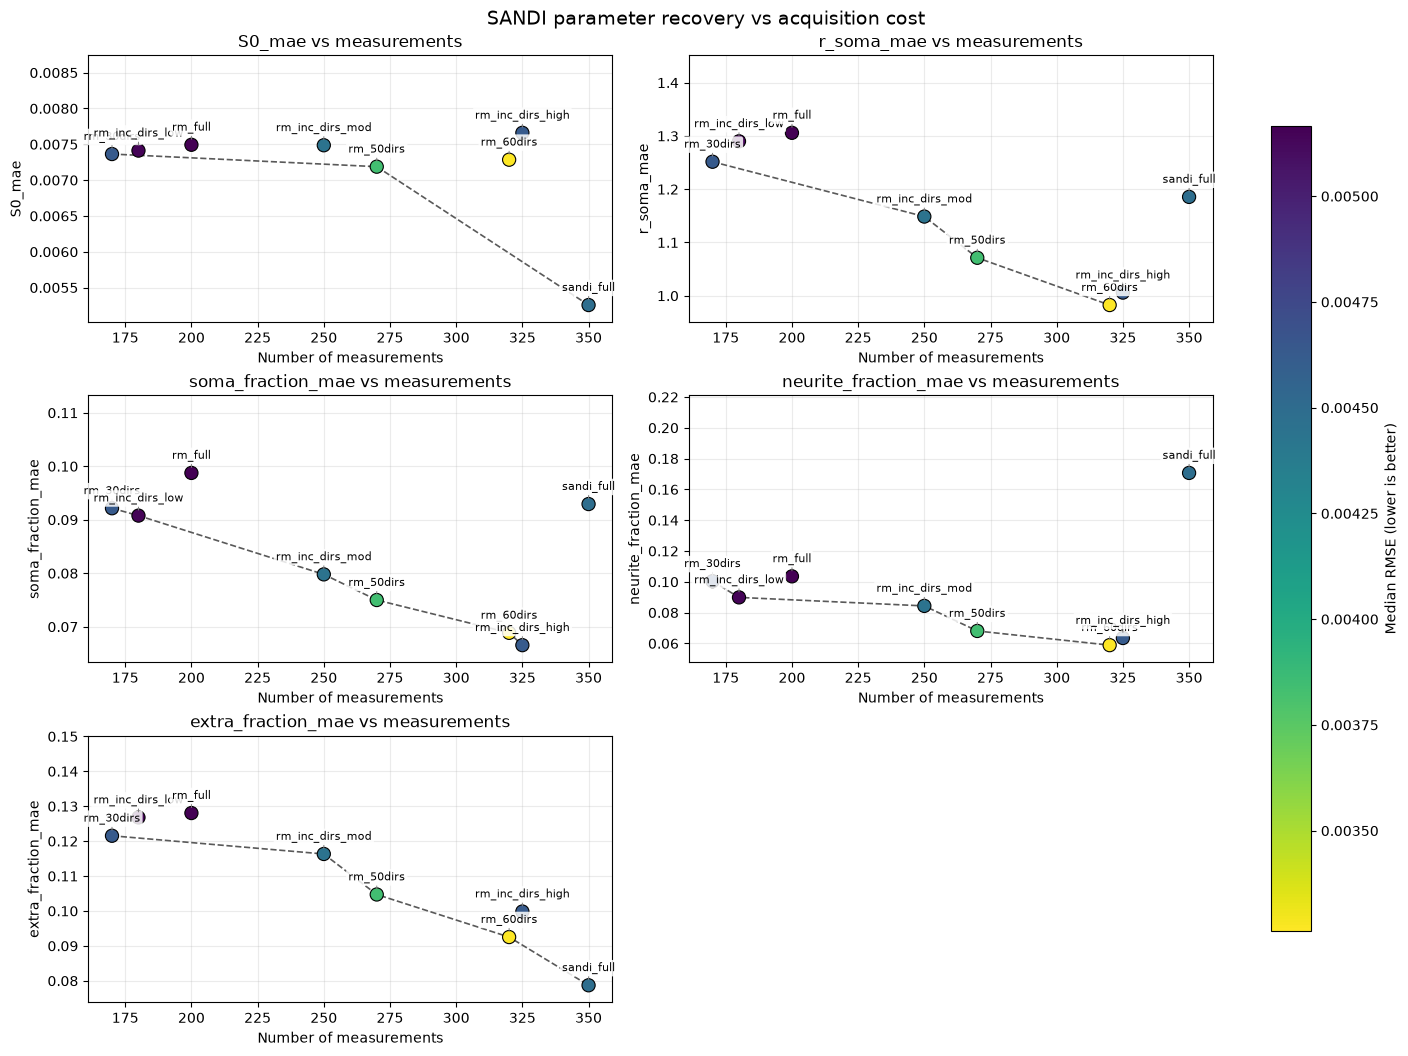

In [15]:
# -----------------------------------------------------------------------------
# Build a per-acquisition, per-fit_kind table of parameter MAEs
# -----------------------------------------------------------------------------
# Keep only parameters that are actually meaningful for your current SANDI preset.
# If you later free d_sphere / d_in / d_ex, add their MAEs back in below.
mae_map = {
    "S0_mae": "S0_abs_error",
    "r_soma_mae": "r_soma_abs_error",
    "soma_fraction_mae": "soma_fraction_abs_error",
    "neurite_fraction_mae": "neurite_fraction_abs_error",
    "extra_fraction_mae": "extra_fraction_abs_error",
    # Optional if you vary them later:
    # "d_sphere_mae": "d_sphere_abs_error",
    # "d_in_mae": "d_in_abs_error",
    # "d_ex_mae": "d_ex_abs_error",
}

group_cols = ["acquisition", "fit_kind"]

per_acq = (
    df.groupby(group_cols)
    .agg(
        # Robustness
        success_rate=("success", "mean"),
        n_evaluations_median=("n_evaluations", "median"),
        failure_count=("success", lambda x: int((~x).sum())),

        # Fit quality
        rmse_median=("rmse", "median"),

        # Main accuracy metrics
        S0_mae=("S0_abs_error", "mean"),
        r_soma_mae=("r_soma_abs_error", "mean"),
        soma_fraction_mae=("soma_fraction_abs_error", "mean"),
        neurite_fraction_mae=("neurite_fraction_abs_error", "mean"),
        extra_fraction_mae=("extra_fraction_abs_error", "mean"),

        # Acquisition cost bookkeeping
        n_measurements=("n_raw_measurements", "first"),
        n_fit_measurements=("n_measurements", "first"),
    )
    .reset_index()
)

# Only keep spherical-mean fits for plotting
plot_per_acq = (
    per_acq[per_acq["fit_kind"] == "sm"]
    .copy()
    .reset_index(drop=True)
)
# Example if you want to exclude something:
# plot_per_acq = per_acq[per_acq["acquisition"] != "uk_biobank"].copy()

# -----------------------------------------------------------------------------
# Pareto frontier helper
# -----------------------------------------------------------------------------
def pareto_mask(x: np.ndarray, y: np.ndarray) -> np.ndarray:
    """
    Returns a boolean mask for non-dominated points.
    Lower x and lower y are better.
    """
    n = len(x)
    mask = np.ones(n, dtype=bool)
    for i in range(n):
        if not mask[i]:
            continue
        dominated = (x <= x[i]) & (y <= y[i]) & ((x < x[i]) | (y < y[i]))
        if np.any(dominated):
            mask[i] = False
    return mask

# -----------------------------------------------------------------------------
# Plot helper
# -----------------------------------------------------------------------------
def plot_metric_vs_measurements(
    ax,
    table,
    metric,
    title=None,
    label_step=14,
    base_offset=8,
):
    # Use raw measurement count as the acquisition-cost axis.
    x = table["n_measurements"].to_numpy()
    y = table[metric].to_numpy()
    c = table["rmse_median"].to_numpy()

    norm = Normalize(vmin=table["rmse_median"].min(), vmax=table["rmse_median"].max())

    sc = ax.scatter(
        x,
        y,
        c=c,
        cmap="viridis_r",   # lower RMSE = brighter
        norm=norm,
        s=90,
        edgecolor="black",
        linewidth=0.8,
        zorder=3,
    )

    # Give the axis a bit of headroom for stacked labels.
    y_min = np.nanmin(y)
    y_max = np.nanmax(y)
    y_span = y_max - y_min if y_max > y_min else 1.0
    ax.set_ylim(y_min - 0.10 * y_span, y_max + 0.45 * y_span)

    # Sort so within each x-group, the best metric value gets the closest label.
    plot_table = table.sort_values(
        ["n_measurements", metric, "acquisition", "fit_kind"],
        ascending=[True, True, True, True],
    ).copy()

    # One vertical stack per x-value.
    for xval, grp in plot_table.groupby("n_measurements", sort=True):
        grp = grp.sort_values(metric, ascending=True).reset_index(drop=True)

        for j, row in grp.iterrows():
            label = f"{row['acquisition']}"

            ax.annotate(
                label,
                xy=(row["n_measurements"], row[metric]),
                xytext=(0, base_offset + label_step * j),
                textcoords="offset points",
                ha="center",
                va="bottom",
                fontsize=8,
                bbox=dict(
                    boxstyle="round,pad=0.2",
                    facecolor="white",
                    edgecolor="none",
                    alpha=0.85,
                ),
                arrowprops=dict(
                    arrowstyle="-",
                    color="0.5",
                    lw=0.7,
                    shrinkA=0,
                    shrinkB=4,
                ),
                zorder=4,
            )

    # Pareto frontier line
    pmask = pareto_mask(x, y)
    pareto = table.loc[pmask].sort_values("n_measurements")
    ax.plot(
        pareto["n_measurements"],
        pareto[metric],
        linestyle="--",
        linewidth=1.2,
        color="0.35",
        zorder=2,
    )

    ax.set_xlabel("Number of measurements")
    ax.set_ylabel(metric)
    ax.set_title(title or metric)
    ax.grid(True, alpha=0.25)

    return sc

# -----------------------------------------------------------------------------
# Make one subplot per metric
# -----------------------------------------------------------------------------
metrics = list(mae_map.keys())

ncols = 2
nrows = int(np.ceil(len(metrics) / ncols))

fig, axes = plt.subplots(
    nrows,
    ncols,
    figsize=(14, 3.4 * nrows),
    constrained_layout=True,
)

axes = np.array(axes).reshape(-1)

last_sc = None
for ax, metric in zip(axes, metrics):
    last_sc = plot_metric_vs_measurements(
        ax=ax,
        table=plot_per_acq,
        metric=metric,
        title=f"{metric} vs measurements",
    )

# Hide any unused axes
for ax in axes[len(metrics):]:
    ax.axis("off")

cbar = fig.colorbar(last_sc, ax=axes.tolist(), shrink=0.85)
cbar.set_label("Median RMSE (lower is better)")

fig.suptitle("SANDI parameter recovery vs acquisition cost", y=1.02, fontsize=14)
plt.show()